# 03_preprocessing_v2.ipynb

## v1 대비 변경 사항
- 로드 파일: `hnm_churn_dataset_v2.csv`
- 결측치 처리: 신규 피처 6개 NaN 처리 전략 추가
- 저장 파일: `hnm_churn_processed_v2.csv`

## 목차
1. 환경 세팅 및 데이터 로드
2. 결측치 처리
3. 메모리 다운캐스팅
4. 피처 인코딩
5. 전처리 완료 데이터 저장 및 검증
6. 데이터셋 분할


## 1. 환경 세팅 및 데이터 로드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

plt.rc('font', family='Malgun Gothic')  # Mac: 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')

df_analysis = pd.read_csv('../data/hnm_churn_dataset_v2.csv')

print(f'데이터 shape: {df_analysis.shape}')
print(f'결측치 합계: {df_analysis.isnull().sum().sum()}')


데이터 shape: (1143652, 26)
결측치 합계: 3476901


## 2. 결측치 처리

In [2]:
# 2-1. FN, Active → 0 대치 (마케팅 미동의 의미)
df_analysis['FN']     = df_analysis['FN'].fillna(0)
df_analysis['Active'] = df_analysis['Active'].fillna(0)
print('FN, Active 처리 완료')


FN, Active 처리 완료


In [3]:
# 2-2. age → 중앙값 대치
age_median = df_analysis['age'].median()
df_analysis['age'] = df_analysis['age'].fillna(age_median)
print(f'age 중앙값 대치 완료: {age_median}')


age 중앙값 대치 완료: 32.0


In [4]:
# 2-3. 범주형 변수 → UNKNOWN 대치
cat_missing_cols = ['club_member_status', 'fashion_news_frequency']
for col in cat_missing_cols:
    df_analysis[col] = df_analysis[col].fillna('UNKNOWN')
print('범주형 결측치 처리 완료')


범주형 결측치 처리 완료


In [5]:
# 2-4. 트리 모델 위임 피처 → NaN 유지
# 아래 피처들은 의도적으로 NaN을 유지합니다.
# - avg/std_purchase_interval, last_interval: 구매 1회 고객은 간격 계산 불가
# - freq_decay_rate, recent_price_ratio, interval_acceleration:
#   결측 자체가 '최근 구매 없음'을 의미 → 이탈 신호
#   트리 모델(LightGBM, XGBoost, CatBoost)은 NaN 자체 처리 가능
#
# 선형/거리 기반 모델 사용 시 아래 주석 해제:
# median_cols = ['avg_purchase_interval', 'std_purchase_interval',
#                'last_interval', 'freq_decay_rate',
#                'recent_price_ratio', 'interval_acceleration']
# for col in median_cols:
#     df_analysis[col] = df_analysis[col].fillna(df_analysis[col].median())

print('NaN 유지 피처 확인:')
nan_cols = ['avg_purchase_interval','std_purchase_interval','last_interval',
            'freq_decay_rate','recent_price_ratio','interval_acceleration']
for col in nan_cols:
    print(f'  {col:<30}: {df_analysis[col].isnull().sum():,}건 NaN 유지')


NaN 유지 피처 확인:
  avg_purchase_interval         : 111,962건 NaN 유지
  std_purchase_interval         : 218,880건 NaN 유지
  last_interval                 : 111,962건 NaN 유지
  freq_decay_rate               : 465,117건 NaN 유지
  recent_price_ratio            : 684,497건 NaN 유지
  interval_acceleration         : 373,193건 NaN 유지


## 3. 메모리 다운캐스팅

In [6]:
# 범주형 → category
cat_encode_cols = ['club_member_status','fashion_news_frequency',
                   'index_group_name','product_group_name']
for col in cat_encode_cols:
    df_analysis[col] = df_analysis[col].astype('category')

# 정수형 다운캐스팅
int_cols = ['churn','recency','frequency','frequency_last_90d',
            'frequency_last_180d','unique_articles',
            'unique_product_groups','unique_articles_last_90d']
for col in int_cols:
    if col == 'churn':
        df_analysis[col] = df_analysis[col].astype('int8')
    else:
        df_analysis[col] = df_analysis[col].astype('int32')

# 실수형 다운캐스팅
float32_cols = ['age','price_mean','price_sum','price_max',
                'avg_purchase_interval','std_purchase_interval',
                'freq_decay_rate','recent_price_ratio',
                'diversity_decay_rate','last_interval','interval_acceleration']
for col in float32_cols:
    df_analysis[col] = df_analysis[col].astype('float32')

df_analysis['FN']     = df_analysis['FN'].astype('float16')
df_analysis['Active'] = df_analysis['Active'].astype('float16')

print('다운캐스팅 완료')
df_analysis.info()


다운캐스팅 완료
<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 26 columns):
 #   Column                    Non-Null Count    Dtype   
---  ------                    --------------    -----   
 0   customer_id               1143652 non-null  str     
 1   churn                     1143652 non-null  int8    
 2   frequency                 1143652 non-null  int32   
 3   price_mean                1143652 non-null  float32 
 4   price_sum                 1143652 non-null  float32 
 5   price_max                 1143652 non-null  float32 
 6   recency                   1143652 non-null  int32   
 7   frequency_last_90d        1143652 non-null  int32   
 8   frequency_last_180d       1143652 non-null  int32   
 9   avg_purchase_interval     1031690 non-null  float32 
 10  std_purchase_interval     924772 non-null   float32 
 11  unique_articles           1143652 non-null  int32   
 12  unique_product_groups     1143652 non-null  int32   
 13  index_group_na

## 4. 피처 인코딩

In [7]:
# 4-1. 원-핫 인코딩 (drop_first=False: 트리 모델에서 정보 손실 방지)
df_encoded = pd.get_dummies(df_analysis, columns=cat_encode_cols,
                             drop_first=False, dtype='int8')

# 4-2. customer_id 제거
if 'customer_id' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['customer_id'])

print(f'인코딩 완료: {df_encoded.shape}')

# 4-3. churn 상관관계 상위 확인 (누수 체크)
corr_with_churn = df_encoded.astype('float32').corr()['churn'].drop('churn')
print('\n--- churn과 상관관계 상위 5개 ---')
print(corr_with_churn.abs().sort_values(ascending=False).head(5).round(4).to_string())


인코딩 완료: (1143652, 51)

--- churn과 상관관계 상위 5개 ---
recency                  0.4812
unique_product_groups    0.4695
unique_articles          0.3768
frequency                0.3587
frequency_last_180d      0.3542


## 5. 전처리 완료 데이터 저장 및 검증

In [9]:
df_encoded.to_csv('../data/hnm_churn_processed_v2.csv', index=False)

df_check = pd.read_csv('../data/hnm_churn_processed_v2.csv')
print(f'저장 완료: {df_check.shape}')
print(f'결측치 합계: {df_check.isnull().sum().sum()}')
# avg/std_purchase_interval, last_interval, freq_decay_rate 등 NaN 유지 → 0이 아니어도 정상
print(f'컬럼 목록:\n{list(df_check.columns)}')


저장 완료: (1143652, 51)
결측치 합계: 1965611
컬럼 목록:
['churn', 'frequency', 'price_mean', 'price_sum', 'price_max', 'recency', 'frequency_last_90d', 'frequency_last_180d', 'avg_purchase_interval', 'std_purchase_interval', 'unique_articles', 'unique_product_groups', 'freq_decay_rate', 'recent_price_ratio', 'unique_articles_last_90d', 'diversity_decay_rate', 'last_interval', 'interval_acceleration', 'FN', 'Active', 'age', 'club_member_status_ACTIVE', 'club_member_status_LEFT CLUB', 'club_member_status_PRE-CREATE', 'club_member_status_UNKNOWN', 'fashion_news_frequency_Monthly', 'fashion_news_frequency_NONE', 'fashion_news_frequency_Regularly', 'fashion_news_frequency_UNKNOWN', 'index_group_name_Baby/Children', 'index_group_name_Divided', 'index_group_name_Ladieswear', 'index_group_name_Menswear', 'index_group_name_Sport', 'product_group_name_Accessories', 'product_group_name_Bags', 'product_group_name_Cosmetic', 'product_group_name_Furniture', 'product_group_name_Garment Full body', 'product_group

## 6. 데이터셋 분할

In [10]:
X = df_encoded.drop(columns=['churn'])
y = df_encoded['churn']

# random_state=42 고정 → 04~07 모델 노트북과 동일한 분할 보장
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')
print(f'y_train 이탈률: {y_train.mean():.4f}')
print(f'y_val   이탈률: {y_val.mean():.4f}')


X_train: (914921, 50), X_val: (228731, 50)
y_train 이탈률: 0.5002
y_val   이탈률: 0.5002


In [12]:
# 분할 데이터 저장
X_train.to_csv('../data/X_train_v2.csv', index=False)
X_val.to_csv('../data/X_val_v2.csv',     index=False)
y_train.to_csv('../data/y_train_v2.csv', index=False)
y_val.to_csv('../data/y_val_v2.csv',     index=False)

print('분할 데이터 저장 완료')
print(f'  X_train_v2.csv : {X_train.shape}')
print(f'  X_val_v2.csv   : {X_val.shape}')


분할 데이터 저장 완료
  X_train_v2.csv : (914921, 50)
  X_val_v2.csv   : (228731, 50)


C:\Users\09048\AppData\Local\Temp\ipykernel_11452\3974456704.py:7: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_11452\3974456704.py:7: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_11452\3974456704.py:7: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_11452\3974456704.py:7: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53944 (\N{H

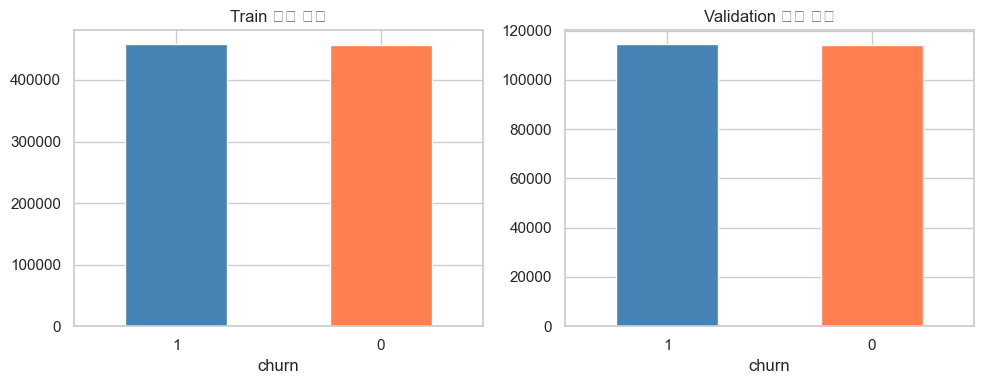

In [13]:
# 분할 후 클래스 비율 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot(kind='bar', ax=axes[0], title='Train 세트 분포',
                             color=['steelblue','coral'], rot=0)
y_val.value_counts().plot(kind='bar',   ax=axes[1], title='Validation 세트 분포',
                           color=['steelblue','coral'], rot=0)
plt.tight_layout()
plt.show()
